# Phase transitions in the Heisenberg model

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables

using Random: MersenneTwister
using Makie

using MPI
MPI.Init();

Function that performs temperature scans

In [7]:
function temperature_scan(L::Int, χ_init::Int, T_range;
                          n_mcs::Int, n_warmup_mcs::Int, seed::Int=123456)
    @assert mod(L, 3) == 0
    @assert χ_init ∈ (-1, 1)

    E_avg = Float64[]
    E_var = Float64[]
    E_err = Float64[]
    cV = Float64[]

    χ_avg = Float64[]
    χ_var = Float64[]
    χ_err = Float64[]

    rng = MersenneTwister(seed)
    conf = Configuration(L, L, χ_init)

    for (n, T) in enumerate(T_range)
        @show T
        sim = MCSimulation(conf, rng, β=1/T, J=1.0, V=.0, λ=.0)
        acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
        @show acceptance_rate

        push!(E_avg, avg_energy(sim))
        push!(E_var, var_energy(sim))
        push!(cV, specific_heat(sim))
        push!(χ_avg, avg_chirality(sim))
        push!(χ_var, var_chirality(sim))

        conf = deepcopy(sim.conf)
    end

    return E_avg, E_var, cV, χ_avg, χ_var
end

temperature_scan (generic function with 1 method)

A few temperature scans with various system sizes

In [8]:
L = 27
T_range = vcat(collect(0.05:0.05:0.395), collect(0.4:0.002:0.7));

n_warmup_mcs = 20_000;
n_mcs = 20_000;

E_avg, E_var, cV, χ_avg, χ_var = temperature_scan(L, 1, T_range; n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)

T = 0.05


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:00:34


acceptance_rate = 0.06617777777777778
T = 0.1


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:00:36


acceptance_rate = 0.0946917352537723
T = 0.15


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:00:36


... (308 outputs left out)

acceptance_rate = 0.3686132030178326
T = 0.7


[Rank 0/1] Running MC simulation 100%|███████████████████| Time: 0:00:43


acceptance_rate = 0.3695598765432099


([-1075.0454736464585, -1056.1960210346444, -1036.7169984729248, -1016.4629474747471, -995.1988239899348, -972.7896789221924, -948.2254733621332, -919.7781412873898, -919.3651417582978, -917.751453622637  …  -652.3690850820094, -651.70542683548, -650.6767107398425, -649.0594875136834, -648.5808329231586, -647.7654355865225, -646.9472997114115, -645.4876698508601, -645.413299309078, -643.9075866685615], [0.9516970371257083, 1.9356796335141766, 2.9660685104809876, 4.048154755135278, 5.150562750463365, 6.469691999981593, 7.841352949385356, 10.15941577641296, 9.854868034818901, 10.06203216103858  …  15.241621338428223, 15.182152864799054, 15.038524017311811, 15.14674603527389, 15.152904170742183, 15.055608617899487, 14.98127954298825, 14.992843919854455, 15.150394232528425, 14.77243665444152], [362.2909001895407, 374.6855643601577, 391.00277372741795, 409.6889230381091, 424.4527463433719, 465.0768286069536, 501.9331924639544, 645.0858057376784, 600.9654710508115, 620.3098422322242  …  499.

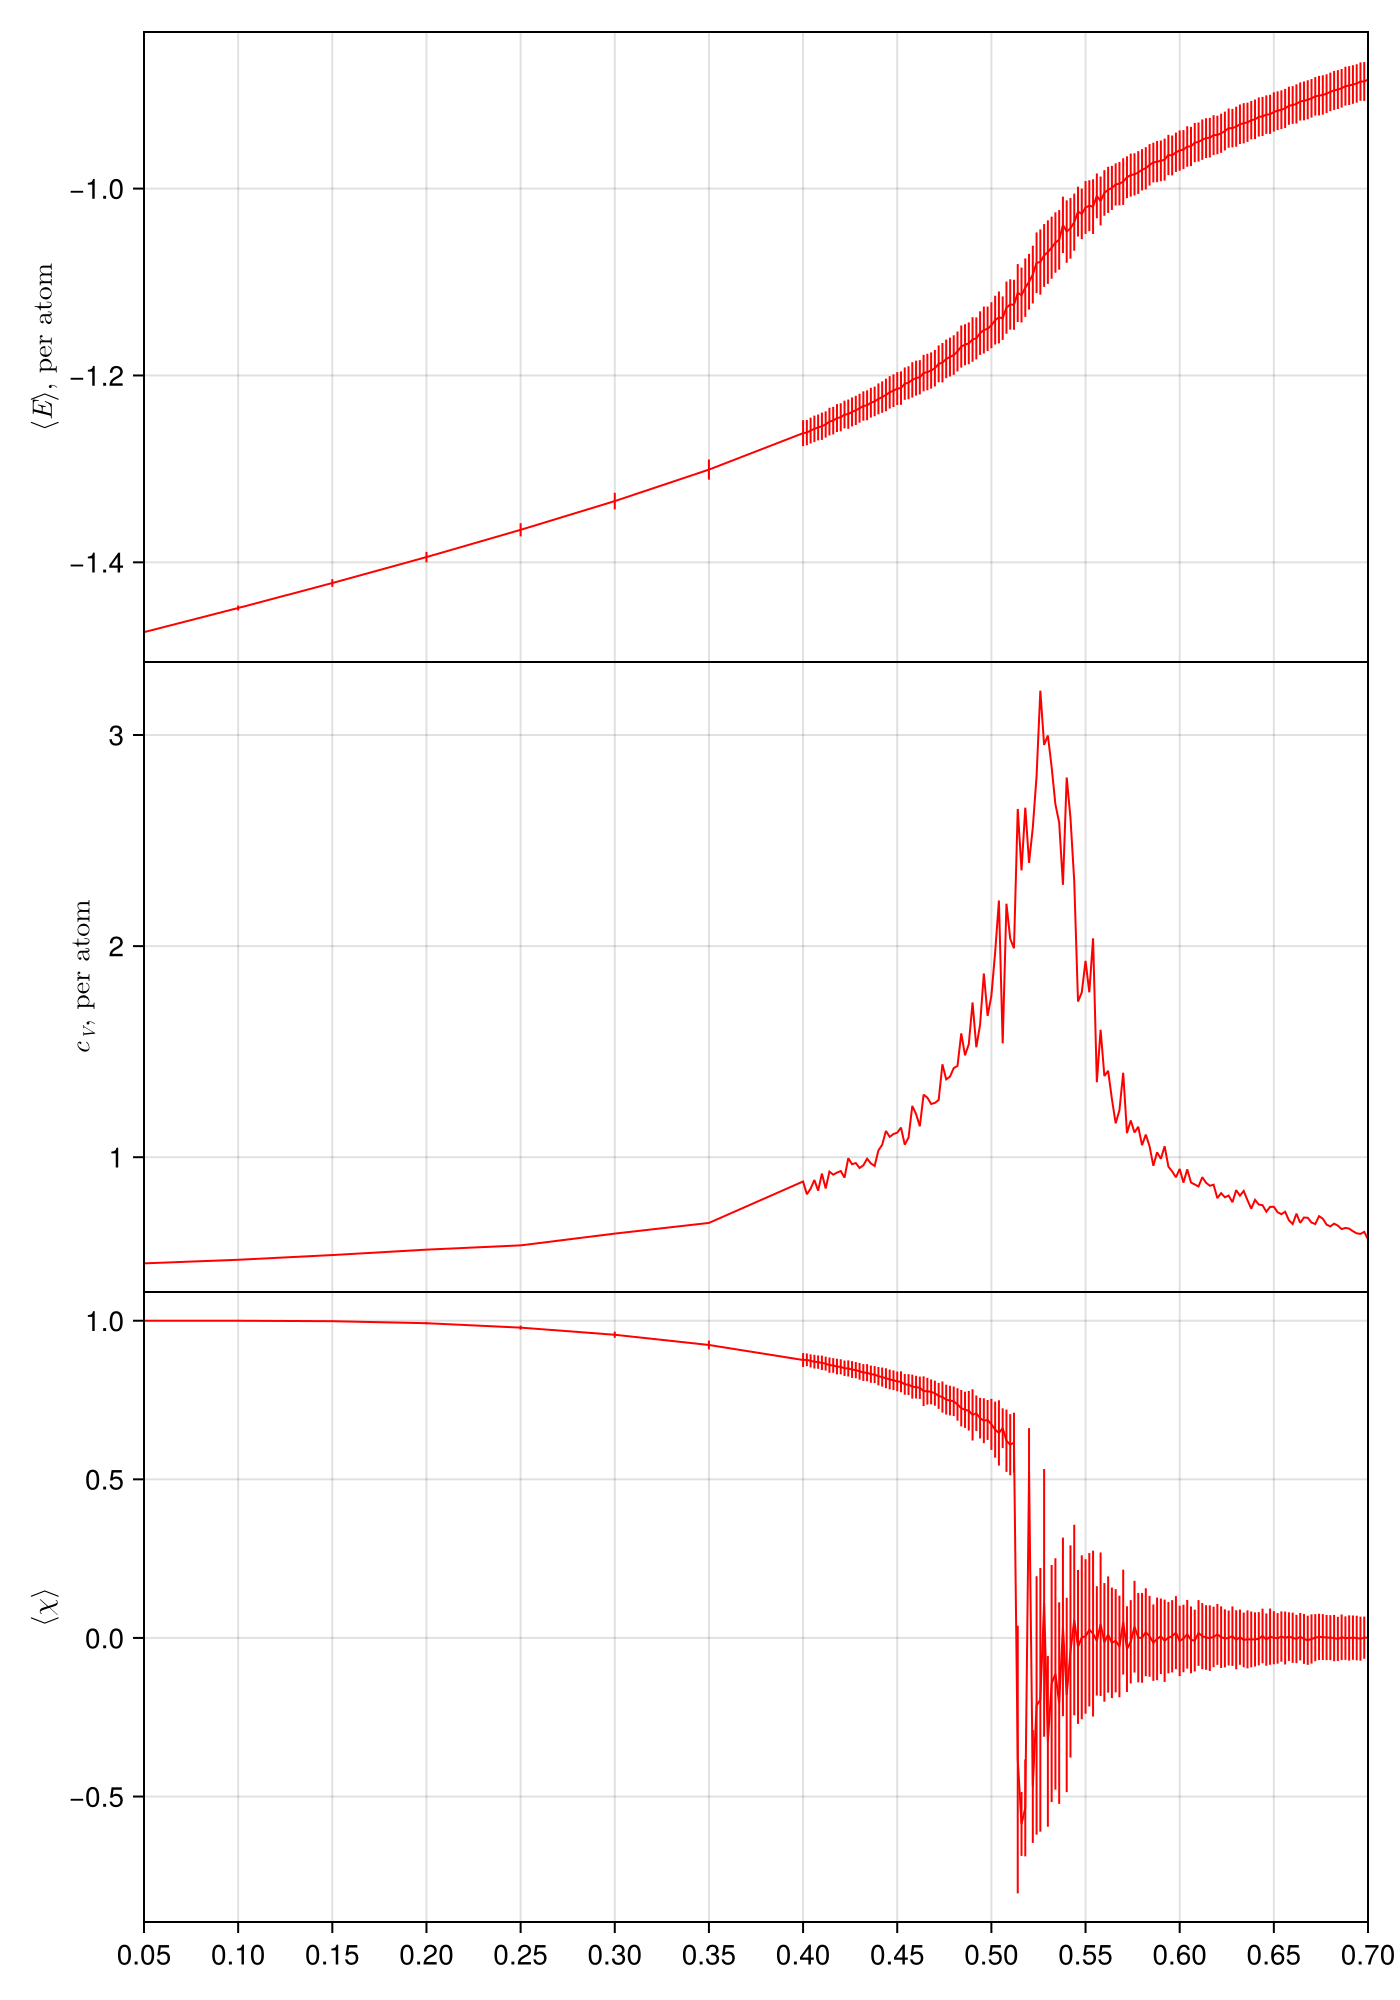

In [12]:
N = L^2

fig = Figure(size=(700, 1000))
xticks = collect(first(T_range):first(T_range):last(T_range))

ax1 = Axis(fig[1, 1], ylabel=L"$\langle E\rangle$, per atom", xticklabelsvisible=false, xticksvisible=false, xticks = xticks)
lines!(ax1, T_range, E_avg / N, linewidth=1, color=:red)
errorbars!(ax1, T_range, E_avg / N, E_var / N, linewidth=1, color=:red)

ax2 = Axis(fig[2, 1], ylabel=L"$c_V$, per atom", xticklabelsvisible=false, xticksvisible=false, xticks = xticks)
linkxaxes!(ax1, ax2)
lines!(ax2, T_range, cV / N, linewidth=1, color=:red)

ax3 = Axis(fig[3, 1], ylabel=L"$\langle\chi\rangle$", xticks = xticks)
linkxaxes!(ax2, ax3)
lines!(ax3, T_range, χ_avg, linewidth=1, color=:red)
errorbars!(ax3, T_range, χ_avg, χ_var, linewidth=1, color=:red)

xlims!(first(T_range), last(T_range))
rowgap!(fig.layout, 0)

save("heisenberg_phase_trans.pdf", fig)
fig